# Fine-tuning de um SLM vs. baselines: um experimento reprodutível

**Pergunta orientadora:** fine-tunar (LoRA) um SLM de 0,5B melhora a classificação de sentimento em português em relação a usá-lo só com prompt, e essa melhora é maior que o ruído entre seeds?

**Como usar:** Ambiente de execução → Alterar tipo → **GPU T4** → Executar tudo. Tempo estimado: ~5 a 8 min por seed (5 seeds ≈ 30 a 40 min). Resultados são salvos no Drive e a execução é retomável se a sessão cair.

| Seção | Tópico coberto |
|---|---|
| 1 | Hipótese, unidade experimental, variáveis |
| 2 | Configuração congelada e comparação justa |
| 3 | Execução com repetição por seed |
| 4 | Média, dispersão, IC 95% |
| 5 | Análise de erros e resultados negativos |
| 6 | Rastreabilidade (manifests) |
| 7 | Executar vs. reproduzir vs. replicar |
| 8 | Relatório final |

## 1. Hipótese, unidade experimental e variáveis

- **Hipótese (H1):** o SLM com LoRA tem F1-macro maior que o mesmo SLM com few-shot, no mesmo teste. **H0:** a diferença média entre seeds é zero.
- **Unidade experimental:** uma execução completa (amostra de treino + treino + avaliação) com uma seed. O teste é fixo; as 5 seeds são as repetições.
- **Variável independente:** método (`tfidf_lr`, `zeroshot`, `fewshot`, `lora`).
- **Variável dependente:** F1-macro (principal) e acurácia.
- **Variáveis de confusão controladas:** split de teste, amostra de treino (mesma para todos os métodos dentro da seed), template do prompt, rótulos, `max_len`, modelo base, tamanho de treino.
- **Variáveis de confusão não controladas (declarar nas limitações):** não determinismo da GPU (fp16), possível contaminação do dataset no pré-treino do Qwen.

In [ ]:
!pip -q install peft datasets scikit-learn scipy

In [ ]:
import os, json, random, hashlib, platform, datetime, importlib.metadata as imd
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

try:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT = "/content/drive/MyDrive/exp_slm_sentimento"
except Exception:
    OUT = "/content/exp_slm_sentimento"
os.makedirs(OUT, exist_ok=True)

assert torch.cuda.is_available(), "Ative a GPU: Ambiente de execução > Alterar tipo > T4"
DEV = "cuda"

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

print("Saída em:", OUT, "| GPU:", torch.cuda.get_device_name(0))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saída em: /content/drive/MyDrive/exp_slm_sentimento | GPU: Tesla T4


## 2. Configuração congelada e comparação justa

Tudo que define o experimento está em `CONFIG`. Depois de rodar, **não edite** durante a coleta: o hash do config entra em cada manifest.

In [ ]:
CONFIG = dict(
    dataset="cardiffnlp/tweet_sentiment_multilingual",  # confira o ID no HF Hub na primeira execução
    subset="portuguese",
    model="Qwen/Qwen2.5-0.5B-Instruct",
    labels=["negativo", "neutro", "positivo"],          # ordem = ids 0,1,2 do dataset
    n_train=1500,
    k_shot=6,                                           # exemplos no few-shot (balanceados)
    lora=dict(r=16, alpha=32, dropout=0.05, target=["q_proj", "k_proj", "v_proj", "o_proj"]),
    epochs=2, lr=2e-4, batch=16,
    seeds=[0, 1, 2, 3, 4],
)
CONFIG_HASH = hashlib.sha256(json.dumps(CONFIG, sort_keys=True).encode()).hexdigest()[:16]
print("config_hash:", CONFIG_HASH)

config_hash: bad39d0fd7f2249a


In [ ]:
# O dataset original usa script (não suportado nas versões novas do `datasets`).
# Lemos direto os parquets da branch convertida do Hub.
from huggingface_hub import list_repo_files, hf_hub_download
REPO, REV = CONFIG["dataset"], "refs/convert/parquet"
files = [f for f in list_repo_files(REPO, repo_type="dataset", revision=REV)
         if f.startswith(CONFIG["subset"] + "/") and f.endswith(".parquet")]
print("parquets encontrados:", files)
assert files, "nenhum parquet para esse subset; veja os arquivos disponíveis com list_repo_files"

def read_split(name):
    fs = [f for f in files if f"/{name}/" in f]
    assert fs, f"split {name} não encontrado em {files}"
    return pd.concat([pd.read_parquet(hf_hub_download(REPO, f, repo_type="dataset", revision=REV)) for f in fs],
                     ignore_index=True)

LABELS = CONFIG["labels"]
def to_df(split):
    d = read_split(split)[["text", "label"]].copy()
    d["text"] = d["text"].str.strip()
    return d

pool, val, test = to_df("train"), to_df("validation"), to_df("test")

# deduplicação treino/teste (evita vazamento)
n0 = len(pool)
pool = pool[~pool.text.isin(set(test.text))].drop_duplicates("text").reset_index(drop=True)
print(f"pool: {n0} -> {len(pool)} após dedup | val: {len(val)} | teste: {len(test)}")
print("distribuição do teste:", test.label.value_counts(normalize=True).round(3).to_dict())
assert set(pool.label) == {0, 1, 2}
TEST_HASH = hashlib.sha256("\n".join(test.text).encode()).hexdigest()[:16]
print("test_hash:", TEST_HASH)

parquets encontrados: ['portuguese/test/0000.parquet', 'portuguese/train/0000.parquet', 'portuguese/validation/0000.parquet']
pool: 1839 -> 1839 após dedup | val: 324 | teste: 870
distribuição do teste: {0: 0.333, 1: 0.333, 2: 0.333}
test_hash: 7509d97cb78f7c97


In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM, get_linear_schedule_with_warmup

tok = AutoTokenizer.from_pretrained(CONFIG["model"])
tok.padding_side = "left"                      # logits do último token = posição da resposta
if tok.pad_token is None: tok.pad_token = tok.eos_token

# classificação restrita: compara só os logits do 1º token de cada rótulo
LABEL_IDS = [tok.encode(" " + w, add_special_tokens=False)[0] for w in LABELS]
assert len(set(LABEL_IDS)) == 3, "primeiros tokens dos rótulos colidem; troque os rótulos"

HEADER = "Classifique o sentimento do tweet em português como negativo, neutro ou positivo.\n\n"
def build_prompt(text, shots=()):
    s = HEADER
    for t, l in shots:
        s += f"Tweet: {t}\nSentimento: {LABELS[l]}\n\n"
    return s + f"Tweet: {text}\nSentimento:"

def pick_shots(train_df, seed):
    rng = np.random.RandomState(seed)
    per = CONFIG["k_shot"] // 3
    shots = []
    for c in range(3):
        sub = train_df[train_df.label == c]
        shots += [(r.text, r.label) for r in sub.iloc[rng.choice(len(sub), per, replace=False)].itertuples()]
    rng.shuffle(shots)
    return shots

def load_base():
    # carrega direto na GPU, sem cópia intermediária na RAM da CPU
    m = AutoModelForCausalLM.from_pretrained(CONFIG["model"], torch_dtype=torch.float32,
                                             device_map={"": 0}, low_cpu_mem_usage=True)
    m.config.use_cache = False
    return m

@torch.no_grad()
def predict(model, prompts, bs=8):
    model.eval(); out = []
    for i in range(0, len(prompts), bs):
        enc = tok(prompts[i:i+bs], return_tensors="pt", padding=True).to(DEV)
        with torch.autocast("cuda", dtype=torch.float16):
            lg = model(**enc).logits[:, -1, :]
        out.append(lg[:, LABEL_IDS].float().argmax(-1).cpu())
    return torch.cat(out).numpy()

def score(y, p):
    return dict(f1_macro=float(f1_score(y, p, average="macro")), acc=float(accuracy_score(y, p)))

def free(*objs):
    import gc; gc.collect(); torch.cuda.empty_cache()

In [ ]:
def finetune(train_df, seed, lr=None, epochs=None):
    from peft import LoraConfig, get_peft_model
    lr = lr or CONFIG["lr"]; epochs = epochs or CONFIG["epochs"]
    set_seed(seed)
    L = CONFIG["lora"]
    model = get_peft_model(load_base(), LoraConfig(r=L["r"], lora_alpha=L["alpha"], lora_dropout=L["dropout"],
                                                   target_modules=L["target"], task_type="CAUSAL_LM"))
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=0.0)
    bs = CONFIG["batch"]
    steps = epochs * int(np.ceil(len(train_df) / bs))
    sch = get_linear_schedule_with_warmup(opt, int(0.06 * steps), steps)
    scaler = torch.amp.GradScaler("cuda")
    prompts = [build_prompt(t) for t in train_df.text]
    y = torch.tensor(train_df.label.values)
    g = torch.Generator().manual_seed(seed)
    losses = []
    model.train()
    for ep in range(epochs):
        perm = torch.randperm(len(prompts), generator=g)
        for i in range(0, len(perm), bs):
            idx = perm[i:i+bs]
            enc = tok([prompts[j] for j in idx], return_tensors="pt", padding=True).to(DEV)
            with torch.autocast("cuda", dtype=torch.float16):
                lg = model(**enc).logits[:, -1, :]
            loss = torch.nn.functional.cross_entropy(lg[:, LABEL_IDS].float(), y[idx].to(DEV))
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            scaler.step(opt); scaler.update(); sch.step()
            losses.append(loss.item())
    return model, losses

## 6. Rastreabilidade (definida antes da execução)

Cada execução grava um `run_*.json` com: hash do config e do teste, versões das bibliotecas, GPU, seed, prompt, métricas e predições. Com isso dá para reconstruir qualquer número da tabela final.

In [ ]:
def env_info():
    libs = ["torch", "transformers", "peft", "datasets", "scikit-learn", "numpy", "pandas"]
    return dict(python=platform.python_version(), gpu=torch.cuda.get_device_name(0),
                libs={l: imd.version(l) for l in libs})

def save_manifest(path, payload):
    payload.update(config=CONFIG, config_hash=CONFIG_HASH, test_hash=TEST_HASH, n_test=len(test),
                   env=env_info(), prompt_header=HEADER,
                   timestamp=datetime.datetime.now(datetime.timezone.utc).isoformat())
    json.dump(payload, open(path, "w"), ensure_ascii=False)
    return payload

y_test = test.label.values

def run_zero_shot():
    path = f"{OUT}/run_zeroshot.json"
    if os.path.exists(path): return json.load(open(path))
    m = load_base()
    p = predict(m, [build_prompt(t) for t in test.text]); free(m)
    return save_manifest(path, dict(method="zeroshot", seed=None, metrics=score(y_test, p), preds=p.tolist()))

def run_seed(seed, tag="main", force=False):
    path = f"{OUT}/run_{tag}_seed{seed}.json"
    if os.path.exists(path) and not force: return json.load(open(path))
    train_df = pool.sample(CONFIG["n_train"], random_state=seed).reset_index(drop=True)
    preds = {}

    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    clf = LogisticRegression(max_iter=1000, random_state=seed).fit(vec.fit_transform(train_df.text), train_df.label)
    preds["tfidf_lr"] = clf.predict(vec.transform(test.text))

    shots = pick_shots(train_df, seed)
    m = load_base()
    preds["fewshot"] = predict(m, [build_prompt(t, shots) for t in test.text]); free(m)

    m, losses = finetune(train_df, seed)
    preds["lora"] = predict(m, [build_prompt(t) for t in test.text]); free(m)

    return save_manifest(path, dict(
        tag=tag, seed=seed, train_hash=hashlib.sha256("\n".join(train_df.text).encode()).hexdigest()[:16],
        n_train=len(train_df), metrics={k: score(y_test, v) for k, v in preds.items()},
        preds={k: v.tolist() for k, v in preds.items()}, final_train_loss=float(np.mean(losses[-10:]))))

## 3. Execução com repetição por seed

A seed controla: amostra de treino, escolha dos exemplos do few-shot, inicialização do LoRA e ordem dos batches. O zero-shot é determinístico (roda uma vez). Se a sessão cair, rode a célula de novo: seeds já salvas são puladas.

In [ ]:
!pip -q uninstall -y torchao

In [ ]:
zs = run_zero_shot()
print("zero-shot:", zs["metrics"])
runs = []
for s in CONFIG["seeds"]:
    r = run_seed(s)
    runs.append(r)
    print(f"seed {s}:", {k: round(v["f1_macro"], 4) for k, v in r["metrics"].items()})

zero-shot: {'f1_macro': 0.16910141953949717, 'acc': 0.33448275862068966}
seed 0: {'tfidf_lr': 0.5737, 'fewshot': 0.5766, 'lora': 0.6986}
seed 1: {'tfidf_lr': 0.5726, 'fewshot': 0.3999, 'lora': 0.7095}
seed 2: {'tfidf_lr': 0.5893, 'fewshot': 0.3713, 'lora': 0.7036}


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

/tmp/ipykernel_7414/2740136003.py:30: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sch.step()


seed 3: {'tfidf_lr': 0.578, 'fewshot': 0.1715, 'lora': 0.7133}


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

/tmp/ipykernel_7414/2740136003.py:30: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sch.step()


seed 4: {'tfidf_lr': 0.5716, 'fewshot': 0.174, 'lora': 0.7122}


In [ ]:
# Checagem de comparação justa: só a variável independente pode mudar
assert all(r["test_hash"] == TEST_HASH for r in runs + [zs]), "teste diferente entre execuções"
assert all(r["config_hash"] == CONFIG_HASH for r in runs + [zs]), "config mudou durante a coleta"
assert all(r["n_train"] == CONFIG["n_train"] for r in runs)
print("OK: mesmo teste, mesmo config, mesmo tamanho de treino para todos os métodos.")

OK: mesmo teste, mesmo config, mesmo tamanho de treino para todos os métodos.


## 4. Média, dispersão e intervalo de confiança

IC 95% entre seeds com t de Student ($n$ pequeno). A comparação principal é **pareada por seed** (lora − fewshot): se o IC da diferença não cruza zero, há evidência de efeito além do ruído; se cruza, o resultado é inconclusivo.

In [ ]:
def ci95(x):
    x = np.asarray(x, float); n = len(x); m = x.mean()
    if n < 2: return m, np.nan, np.nan, np.nan
    s = x.std(ddof=1); h = stats.t.ppf(0.975, n - 1) * s / np.sqrt(n)
    return m, s, m - h, m + h

def boot_ci(y, p, n=1000, seed=0):
    rng = np.random.RandomState(seed); y = np.asarray(y); p = np.asarray(p); v = []
    for _ in range(n):
        i = rng.randint(0, len(y), len(y)); v.append(f1_score(y[i], p[i], average="macro"))
    return np.percentile(v, [2.5, 97.5])

rows = []
for meth in ["tfidf_lr", "fewshot", "lora"]:
    f1s = [r["metrics"][meth]["f1_macro"] for r in runs]
    m, s, lo, hi = ci95(f1s)
    rows.append(dict(metodo=meth, n_seeds=len(f1s), f1_media=m, desvio=s, ic95_lo=lo, ic95_hi=hi))
lo, hi = boot_ci(y_test, zs["preds"])
rows.append(dict(metodo="zeroshot", n_seeds=1, f1_media=zs["metrics"]["f1_macro"], desvio=np.nan, ic95_lo=lo, ic95_hi=hi))
summary = pd.DataFrame(rows).round(4)
display(summary)

print("\nDiferenças pareadas por seed (F1-macro):")
for a, b in [("lora", "fewshot"), ("lora", "tfidf_lr"), ("fewshot", "tfidf_lr")]:
    d = [r["metrics"][a]["f1_macro"] - r["metrics"][b]["f1_macro"] for r in runs]
    m, s, lo, hi = ci95(d)
    veredito = "IC cruza zero (inconclusivo)" if lo <= 0 <= hi else ("efeito positivo" if m > 0 else "efeito negativo")
    print(f"  {a} - {b}: {m:+.4f}  IC95% [{lo:+.4f}, {hi:+.4f}]  -> {veredito}")

,metodo,n_seeds,f1_media,desvio,ic95_lo,ic95_hi
0,tfidf_lr,5,0.5770,0.0073,0.5680,0.5861
1,fewshot,5,0.3387,0.1706,0.1268,0.5505
2,lora,5,0.7074,0.0062,0.6998,0.7151
3,zeroshot,1,0.1691,NaN,0.1561,0.1823



Diferenças pareadas por seed (F1-macro):
  lora - fewshot: +0.3688  IC95% [+0.1499, +0.5877]  -> efeito positivo
  lora - tfidf_lr: +0.1304  IC95% [+0.1171, +0.1437]  -> efeito positivo
  fewshot - tfidf_lr: -0.2384  IC95% [-0.4503, -0.0264]  -> efeito negativo


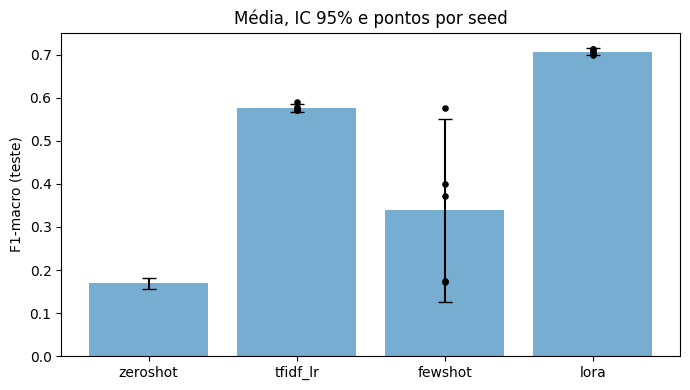

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
order = ["zeroshot", "tfidf_lr", "fewshot", "lora"]
S = summary.set_index("metodo").loc[order]
err = np.vstack([S.f1_media - S.ic95_lo, S.ic95_hi - S.f1_media])
ax.bar(order, S.f1_media, yerr=err, capsize=5, alpha=.6)
for i, meth in enumerate(order[1:], start=1):
    ax.scatter([i] * len(runs), [r["metrics"][meth]["f1_macro"] for r in runs], c="k", s=14, zorder=3)
ax.set_ylabel("F1-macro (teste)"); ax.set_title("Média, IC 95% e pontos por seed")
plt.tight_layout(); plt.savefig(f"{OUT}/f1_por_metodo.png", dpi=150); plt.show()

## 5. Análise de erros e resultados negativos

Abaixo: matriz de confusão do melhor método e 20 erros para **categorizar à mão** (ironia, negação, gíria, rótulo duvidoso, tweet ambíguo). Preencha a coluna `categoria` no CSV salvo no Drive.

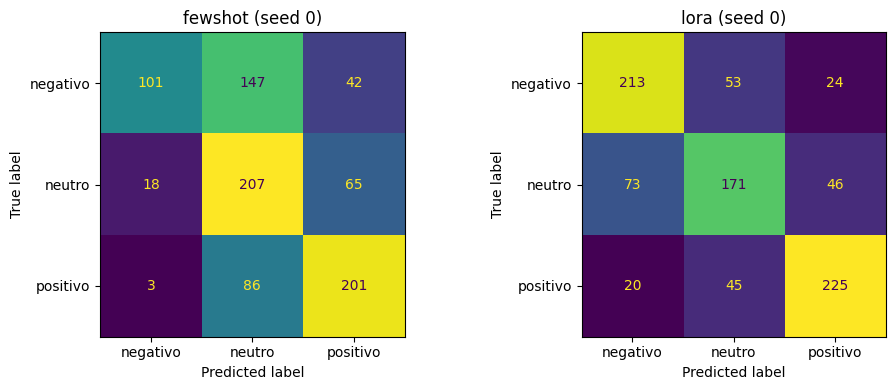

,text,real,pred,categoria
573,Eu to tremendo #MasterChefBR,negativo,positivo,
346,Nunca tinha pensado com o Nabby 😮 #Encontro,neutro,negativo,
819,"Nayane, Victor V ou Deborah tem que sair hoje ...",negativo,neutro,
226,"Eles morrem de rir tb,taquem falha nossa de No...",neutro,negativo,
760,EU QUE TINHA TUDO HOJE ESTOU MUDO ESTOU MUDAD...,neutro,negativo,
590,"#AltasHoras. Estamos juntos, @user . Minha mã...",positivo,neutro,
26,#MasterChefBR Hummm deu vontade de comer uma s...,positivo,neutro,
217,"Quando nossos recursos chegam ao fim, os recur...",neutro,negativo,
115,Eu vou torcer pra metade da repescagem desse j...,neutro,negativo,
535,Mr Catra (@user) falando que vai ser pai pela ...,neutro,negativo,


In [ ]:
r0 = runs[0]; p = np.array(r0["preds"]["lora"])
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, meth in zip(ax, ["fewshot", "lora"]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, r0["preds"][meth]), display_labels=LABELS).plot(ax=a, colorbar=False)
    a.set_title(f"{meth} (seed 0)")
plt.tight_layout(); plt.show()

errs = test.assign(pred=[LABELS[i] for i in p], real=[LABELS[i] for i in y_test])[p != y_test]
errs = errs.sample(20, random_state=0)[["text", "real", "pred"]].assign(categoria="")
errs.to_csv(f"{OUT}/erros_lora_seed0.csv", index=False)
display(errs)

### Resultados negativos

Registre aqui, mesmo sem melhora. Exemplos para tentar e anotar:

- LoRA com *learning rate* alto (célula abaixo): instabilidade esperada.
- Se `lora - fewshot` cruzar zero: o fine-tuning não superou o prompt com este orçamento (isso é um achado, não falha).
- O que o zero-shot errou sistematicamente (ex.: classe `neutro`).

**Anotações:** _(preencha depois de rodar)_

In [ ]:
# Ablação: mesma seed, lr 10x maior. Registrada mesmo que piore.
def run_ablation(seed, lr):
    path = f"{OUT}/run_ablation_lr{lr}_seed{seed}.json"
    if os.path.exists(path): return json.load(open(path))
    train_df = pool.sample(CONFIG["n_train"], random_state=seed).reset_index(drop=True)
    m, losses = finetune(train_df, seed, lr=lr)
    p = predict(m, [build_prompt(t) for t in test.text]); free(m)
    return save_manifest(path, dict(method="lora_ablation", seed=seed, lr=lr, metrics=score(y_test, p),
                                    preds=p.tolist(), final_train_loss=float(np.mean(losses[-10:]))))

ab = run_ablation(0, 2e-3)
print("lr=2e-3:", ab["metrics"], "| loss final:", round(ab["final_train_loss"], 4))
print("lr=2e-4 (config):", runs[0]["metrics"]["lora"])

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

/tmp/ipykernel_7414/2740136003.py:30: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sch.step()


lr=2e-3: {'f1_macro': 0.16666666666666666, 'acc': 0.3333333333333333} | loss final: 1.1453
lr=2e-4 (config): {'f1_macro': 0.6986008892517398, 'acc': 0.7}


## 6 (cont.). Tabela agregada de todas as execuções

In [ ]:
import glob
rows = []
for f in sorted(glob.glob(f"{OUT}/run_*.json")):
    r = json.load(open(f))
    for meth, m in (r["metrics"].items() if "tag" in r else [(r["method"], r["metrics"])]):
        rows.append(dict(arquivo=os.path.basename(f), metodo=meth, seed=r.get("seed"), f1=round(m["f1_macro"], 4),
                         acc=round(m["acc"], 4), config=r["config_hash"], teste=r["test_hash"], timestamp=r["timestamp"][:19]))
registry = pd.DataFrame(rows); registry.to_csv(f"{OUT}/registro_execucoes.csv", index=False); display(registry)

,arquivo,metodo,seed,f1,acc,config,teste,timestamp
0,run_ablation_lr0.002_seed0.json,lora_ablation,0.0,0.1667,0.3333,bad39d0fd7f2249a,7509d97cb78f7c97,2026-10-20T20:34:17
1,run_main_seed0.json,tfidf_lr,0.0,0.5737,0.5747,bad39d0fd7f2249a,7509d97cb78f7c97,2026-10-20T20:22:35
2,run_main_seed0.json,fewshot,0.0,0.5766,0.5851,bad39d0fd7f2249a,7509d97cb78f7c97,2026-10-20T20:22:35
3,run_main_seed0.json,lora,0.0,0.6986,0.7000,bad39d0fd7f2249a,7509d97cb78f7c97,2026-10-20T20:22:35
4,run_main_seed1.json,tfidf_lr,1.0,0.5726,0.5736,bad39d0fd7f2249a,7509d97cb78f7c97,2026-10-20T20:23:51
5,run_main_seed1.json,fewshot,1.0,0.3999,0.4540,bad39d0fd7f2249a,7509d97cb78f7c97,2026-10-20T20:23:51
6,run_main_seed1.json,lora,1.0,0.7095,0.7069,bad39d0fd7f2249a,7509d97cb78f7c97,2026-10-20T20:23:51
7,run_main_seed2.json,tfidf_lr,2.0,0.5893,0.5920,bad39d0fd7f2249a,7509d97cb78f7c97,2026-10-20T20:25:15
8,run_main_seed2.json,fewshot,2.0,0.3713,0.4575,bad39d0fd7f2249a,7509d97cb78f7c97,2026-10-20T20:25:15
9,run_main_seed2.json,lora,2.0,0.7036,0.7011,bad39d0fd7f2249a,7509d97cb78f7c97,2026-10-20T20:25:15


## 7. Executar vs. reproduzir vs. replicar

- **Executar:** rodar o notebook uma vez (seção 3).
- **Reproduzir:** mesmo código, dados, config e seed → métricas iguais (dentro de tolerância; fp16 em GPU não é bit-a-bit determinístico).
- **Replicar:** mudança legítima (novas amostras de treino, seeds 100 a 102) → a **conclusão** se mantém?

In [ ]:
# Reproduzir: refaz a seed 0 e compara com o manifest original
orig = json.load(open(f"{OUT}/run_main_seed0.json"))
again = run_seed(0, tag="repro", force=True)
TOL = 0.02
for meth in ["tfidf_lr", "fewshot", "lora"]:
    a, b = orig["metrics"][meth]["f1_macro"], again["metrics"][meth]["f1_macro"]
    print(f"{meth}: original={a:.4f} reproduzido={b:.4f} dif={abs(a-b):.4f}")
    assert abs(a - b) <= TOL, f"{meth} não reproduziu dentro de {TOL}"
print("Reproduzido dentro da tolerância.")

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

/tmp/ipykernel_7414/2740136003.py:30: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sch.step()


tfidf_lr: original=0.5737 reproduzido=0.5737 dif=0.0000
fewshot: original=0.5766 reproduzido=0.5766 dif=0.0000
lora: original=0.6986 reproduzido=0.6986 dif=0.0000
Reproduzido dentro da tolerância.


In [ ]:
# Replicar: novas amostras de treino (seeds 100-102), mesma conclusão?
rep = [run_seed(s, tag="repl") for s in [100, 101, 102]]
d_orig = np.mean([r["metrics"]["lora"]["f1_macro"] - r["metrics"]["fewshot"]["f1_macro"] for r in runs])
d_rep  = np.mean([r["metrics"]["lora"]["f1_macro"] - r["metrics"]["fewshot"]["f1_macro"] for r in rep])
print(f"lora - fewshot | original: {d_orig:+.4f} | replicação: {d_rep:+.4f}")
print("Mesma direção:", np.sign(d_orig) == np.sign(d_rep))

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

/tmp/ipykernel_7414/2740136003.py:30: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sch.step()


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

/tmp/ipykernel_7414/2740136003.py:30: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sch.step()


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

/tmp/ipykernel_7414/2740136003.py:30: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sch.step()


lora - fewshot | original: +0.3688 | replicação: +0.4508
Mesma direção: True


## 8. Relatório final (5 linhas)

In [ ]:
d = [r["metrics"]["lora"]["f1_macro"] - r["metrics"]["fewshot"]["f1_macro"] for r in runs]
m, s, lo, hi = ci95(d)
S2 = summary.set_index("metodo")
print(f'''
1. Hipótese: LoRA > few-shot em F1-macro no mesmo teste ({len(test)} tweets), {len(runs)} seeds, modelo {CONFIG["model"]}.
2. Resultado: lora {S2.loc["lora","f1_media"]:.3f} | fewshot {S2.loc["fewshot","f1_media"]:.3f} | zeroshot {S2.loc["zeroshot","f1_media"]:.3f} | tfidf_lr {S2.loc["tfidf_lr","f1_media"]:.3f}; diferença lora-fewshot {m:+.3f} IC95% [{lo:+.3f}, {hi:+.3f}] ({"cruza zero" if lo <= 0 <= hi else "não cruza zero"}).
3. Limitações: poucas seeds (IC largo), um dataset, um modelo, possível contaminação, fp16 não determinístico.
4. Erros principais: ver erros_lora_seed0.csv (categorizar) e a ablação de lr.
5. Reprodução: Executar tudo na T4; config_hash={CONFIG_HASH}, test_hash={TEST_HASH}; manifests em {OUT}.
''')


1. Hipótese: LoRA > few-shot em F1-macro no mesmo teste (870 tweets), 5 seeds, modelo Qwen/Qwen2.5-0.5B-Instruct.
2. Resultado: lora 0.707 | fewshot 0.339 | zeroshot 0.169 | tfidf_lr 0.577; diferença lora-fewshot +0.369 IC95% [+0.150, +0.588] (não cruza zero).
3. Limitações: poucas seeds (IC largo), um dataset, um modelo, possível contaminação, fp16 não determinístico.
4. Erros principais: ver erros_lora_seed0.csv (categorizar) e a ablação de lr.
5. Reprodução: Executar tudo na T4; config_hash=bad39d0fd7f2249a, test_hash=7509d97cb78f7c97; manifests em /content/drive/MyDrive/exp_slm_sentimento.



In [ ]:
import glob, json
for f in sorted(glob.glob(f"{OUT}/run_main_seed*.json")):
    r = json.load(open(f))
    print(r["seed"], round(r["final_train_loss"], 3), {k: round(v["f1_macro"], 3) for k, v in r["metrics"].items()})

0 0.662 {'tfidf_lr': 0.574, 'fewshot': 0.577, 'lora': 0.699}
1 0.744 {'tfidf_lr': 0.573, 'fewshot': 0.4, 'lora': 0.71}
2 0.734 {'tfidf_lr': 0.589, 'fewshot': 0.371, 'lora': 0.704}
3 0.728 {'tfidf_lr': 0.578, 'fewshot': 0.172, 'lora': 0.713}
4 0.639 {'tfidf_lr': 0.572, 'fewshot': 0.174, 'lora': 0.712}


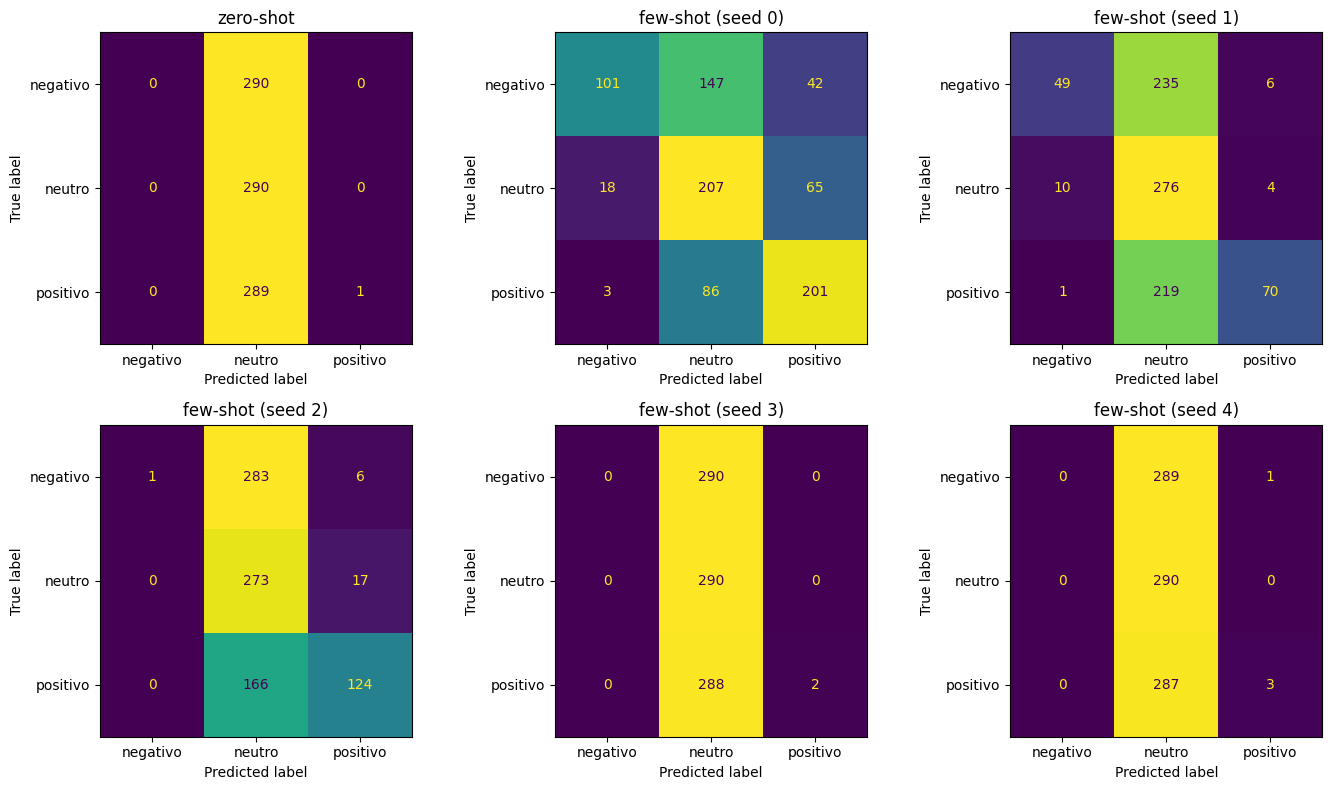

,execucao,negativo,neutro,positivo
0,real (teste),0.333,0.333,0.333
1,zero-shot,0.000,0.999,0.001
2,few-shot (seed 0),0.140,0.506,0.354
3,few-shot (seed 1),0.069,0.839,0.092
4,few-shot (seed 2),0.001,0.830,0.169
5,few-shot (seed 3),0.000,0.998,0.002
6,few-shot (seed 4),0.000,0.995,0.005


In [ ]:
import glob, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, f1_score
from scipy import stats

zs = json.load(open(f"{OUT}/run_zeroshot.json"))
runs = [json.load(open(f"{OUT}/run_main_seed{s}.json")) for s in CONFIG["seeds"]]
y_test = test.label.values

panels = [("zero-shot", zs["preds"])] + [(f"few-shot (seed {r['seed']})", r["preds"]["fewshot"]) for r in runs]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for a, (title, p) in zip(axes.ravel(), panels):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p, labels=[0, 1, 2]), display_labels=LABELS).plot(ax=a, colorbar=False)
    a.set_title(title)
plt.tight_layout(); plt.savefig(f"{OUT}/confusao_zeroshot_fewshot.png", dpi=150); plt.show()

rows = [dict(execucao="real (teste)", **{l: round((y_test == i).mean(), 3) for i, l in enumerate(LABELS)})]
for title, p in panels:
    p = np.array(p)
    rows.append(dict(execucao=title, **{l: round((p == i).mean(), 3) for i, l in enumerate(LABELS)}))
display(pd.DataFrame(rows))

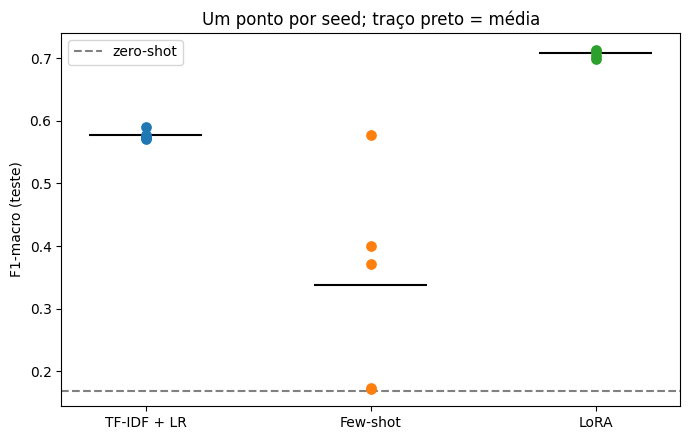

,metodo,media,desvio,ic_lo,ic_hi
0,tfidf_lr,0.5770,0.0073,0.5680,0.5861
1,fewshot,0.3387,0.1706,0.1268,0.5505
2,lora,0.7074,0.0062,0.6998,0.7151


lora - fewshot: +0.3688 IC95% [+0.1499, +0.5877] | seeds a favor de lora: 5/5
lora - tfidf_lr: +0.1304 IC95% [+0.1171, +0.1437] | seeds a favor de lora: 5/5


,tfidf_lr,fewshot,lora
negativo,0.612,0.155,0.718
neutro,0.501,0.530,0.642
positivo,0.618,0.330,0.762


In [ ]:
def ci95(x):
    x = np.asarray(x, float); n = len(x); m = x.mean(); s = x.std(ddof=1)
    h = stats.t.ppf(0.975, n - 1) * s / np.sqrt(n)
    return m, s, m - h, m + h

M = ["tfidf_lr", "fewshot", "lora"]
f1 = {m: [r["metrics"][m]["f1_macro"] for r in runs] for m in M}

# figura: cada ponto é uma seed (mostra a instabilidade do few-shot)
fig, ax = plt.subplots(figsize=(7, 4.5))
for i, m in enumerate(M):
    ax.scatter([i] * len(runs), f1[m], s=45, zorder=3)
    ax.hlines(np.mean(f1[m]), i - .25, i + .25, colors="k")
ax.axhline(zs["metrics"]["f1_macro"], ls="--", c="gray", label="zero-shot")
ax.set_xticks(range(3)); ax.set_xticklabels(["TF-IDF + LR", "Few-shot", "LoRA"])
ax.set_ylabel("F1-macro (teste)"); ax.set_title("Um ponto por seed; traço preto = média"); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT}/f1_por_seed.png", dpi=150); plt.show()

# tabela-resumo
rows = []
for m in M:
    mean, sd, lo, hi = ci95(f1[m])
    rows.append(dict(metodo=m, media=mean, desvio=sd, ic_lo=lo, ic_hi=hi))
summary = pd.DataFrame(rows).round(4); display(summary)

# diferenças pareadas
diffs = {}
for a, b in [("lora", "fewshot"), ("lora", "tfidf_lr")]:
    d = [x - y for x, y in zip(f1[a], f1[b])]
    mean, sd, lo, hi = ci95(d)
    diffs[f"{a}-{b}"] = dict(media=mean, ic_lo=lo, ic_hi=hi, cruza_zero=bool(lo <= 0 <= hi), seeds_positivas=int(sum(x > 0 for x in d)))
    print(f"{a} - {b}: {mean:+.4f} IC95% [{lo:+.4f}, {hi:+.4f}] | seeds a favor de {a}: {sum(x > 0 for x in d)}/{len(d)}")

# F1 por classe (média das seeds)
perclass = pd.DataFrame({m: np.mean([f1_score(y_test, r["preds"][m], average=None, labels=[0, 1, 2]) for r in runs], axis=0)
                         for m in M}, index=LABELS).round(3)
display(perclass)

json.dump(dict(zeroshot_f1=zs["metrics"]["f1_macro"], resumo=summary.to_dict("records"), diferencas=diffs,
               f1_por_classe=perclass.to_dict(), config_hash=runs[0]["config_hash"], test_hash=runs[0]["test_hash"]),
          open(f"{OUT}/resumo_apresentacao.json", "w"), indent=2, ensure_ascii=False)

In [ ]:
orig = json.load(open(f"{OUT}/run_main_seed0.json"))
rep0 = json.load(open(f"{OUT}/run_repro_seed0.json"))
print("REPRODUZIR (seed 0, mesmo código/dados/seed):")
for m in M:
    a, b = orig["metrics"][m]["f1_macro"], rep0["metrics"][m]["f1_macro"]
    print(f"  {m}: original {a:.4f} | reproduzido {b:.4f} | dif {abs(a - b):.4f}")

repl = [json.load(open(f)) for f in sorted(glob.glob(f"{OUT}/run_repl_seed*.json"))]
print("\nREPLICAR (seeds novas, amostras de treino novas):")
for r in repl:
    print(f"  seed {r['seed']}: " + " | ".join(f"{m} {r['metrics'][m]['f1_macro']:.3f}" for m in M))
for a, b in [("lora", "fewshot"), ("lora", "tfidf_lr")]:
    d_o = np.mean([r["metrics"][a]["f1_macro"] - r["metrics"][b]["f1_macro"] for r in runs])
    d_r = np.mean([r["metrics"][a]["f1_macro"] - r["metrics"][b]["f1_macro"] for r in repl])
    print(f"  {a} - {b}: original {d_o:+.3f} | replicação {d_r:+.3f} | mesma direção: {np.sign(d_o) == np.sign(d_r)}")

print("\nABLAÇÃO (lr alto):")
for f in glob.glob(f"{OUT}/run_ablation_*.json"):
    ab = json.load(open(f))
    print(f"  lr={ab['lr']}: F1 {ab['metrics']['f1_macro']:.4f} | loss final {ab['final_train_loss']:.3f}"
          f" | config (lr={CONFIG['lr']}): F1 {orig['metrics']['lora']['f1_macro']:.4f}")

REPRODUZIR (seed 0, mesmo código/dados/seed):
  tfidf_lr: original 0.5737 | reproduzido 0.5737 | dif 0.0000
  fewshot: original 0.5766 | reproduzido 0.5766 | dif 0.0000
  lora: original 0.6986 | reproduzido 0.6986 | dif 0.0000

REPLICAR (seeds novas, amostras de treino novas):
  seed 100: tfidf_lr 0.563 | fewshot 0.368 | lora 0.705
  seed 101: tfidf_lr 0.574 | fewshot 0.185 | lora 0.718
  seed 102: tfidf_lr 0.580 | fewshot 0.234 | lora 0.716
  lora - fewshot: original +0.369 | replicação +0.451 | mesma direção: True
  lora - tfidf_lr: original +0.130 | replicação +0.141 | mesma direção: True

ABLAÇÃO (lr alto):
  lr=0.002: F1 0.1667 | loss final 1.145 | config (lr=0.0002): F1 0.6986


In [ ]:
p = np.array(runs[0]["preds"]["lora"])
cm = confusion_matrix(y_test, p, labels=[0, 1, 2])
pares = sorted([(LABELS[i], LABELS[j], int(cm[i, j])) for i in range(3) for j in range(3) if i != j], key=lambda t: -t[2])
print("Confusões mais frequentes (real -> previsto):")
for r, pr, n in pares: print(f"  {r} -> {pr}: {n}")

erros = pd.read_csv(f"{OUT}/erros_lora_seed0.csv")
pd.set_option("display.max_colwidth", 200)
display(erros[["text", "real", "pred"]])

Confusões mais frequentes (real -> previsto):
  neutro -> negativo: 73
  negativo -> neutro: 53
  neutro -> positivo: 46
  positivo -> neutro: 45
  negativo -> positivo: 24
  positivo -> negativo: 20


,text,real,pred
0,Eu to tremendo #MasterChefBR,negativo,positivo
1,Nunca tinha pensado com o Nabby 😮 #Encontro,neutro,negativo
2,"Nayane, Victor V ou Deborah tem que sair hoje minha nossa senhora #MasterChefBR",negativo,neutro
3,"Eles morrem de rir tb,taquem falha nossa de Novo Mundo,por favor. #VideoShowAoVivo",neutro,negativo
4,EU QUE TINHA TUDO HOJE ESTOU MUDO ESTOU MUDADO 🎶 #Encontro,neutro,negativo
5,"#AltasHoras. Estamos juntos, @user . Minha mãe também era Ana e também brilha no Universo.",positivo,neutro
6,#MasterChefBR Hummm deu vontade de comer uma sardinha com pãozinho kkk partiu abrir uma latinha! 😁,positivo,neutro
7,"Quando nossos recursos chegam ao fim, os recursos de Deus estão todos disponíveis.#SextaDetremuraSDV #MaisVoce #NoisEhFeioMais",neutro,negativo
8,Eu vou torcer pra metade da repescagem desse jeito #MasterChefBR,neutro,negativo
9,Mr Catra (@user) falando que vai ser pai pela 33°vez. 😱😱😱😱😱😱😱😱😱😱😱😱😱😱😂😂😂😂😂😂😂😂 #TheNoite @user @user.,neutro,negativo


,count
categoria,
ironia,3
negação,3
gíria,3
ambíguo/rótulo duvidoso,3
neutro vs. opinião,3
sem contexto,3
outro,2


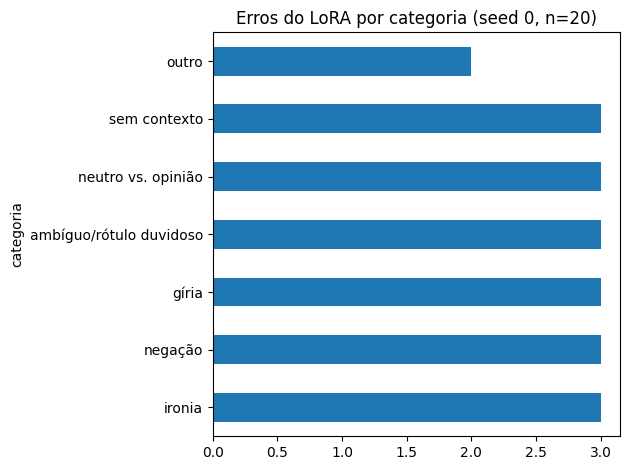

In [ ]:
categorias = ["ironia", "negação", "gíria", "ambíguo/rótulo duvidoso", "neutro vs. opinião",
              "ironia", "sem contexto", "gíria", "negação", "ambíguo/rótulo duvidoso",
              "neutro vs. opinião", "sem contexto", "ironia", "gíria", "outro",
              "ambíguo/rótulo duvidoso", "negação", "neutro vs. opinião", "sem contexto", "outro"]  # troque cada "?" pela categoria do erro, na ordem da tabela

assert len(categorias) == 20 and "?" not in categorias, "preencha as 20 categorias"
erros["categoria"] = categorias
erros.to_csv(f"{OUT}/erros_lora_seed0_categorizado.csv", index=False)
cont = erros.categoria.value_counts()
display(cont)
cont.plot.barh(title="Erros do LoRA por categoria (seed 0, n=20)"); plt.tight_layout()
plt.savefig(f"{OUT}/erros_por_categoria.png", dpi=150); plt.show()

In [ ]:
def free_mem():
    import gc; gc.collect(); torch.cuda.empty_cache()

In [ ]:
@torch.no_grad()
def predict_logp(model, prompts, bs=8):
    model.eval(); out = []
    for i in range(0, len(prompts), bs):
        enc = tok(prompts[i:i+bs], return_tensors="pt", padding=True).to(DEV)
        with torch.autocast("cuda", dtype=torch.float16):
            lg = model(**enc).logits[:, -1, :]
        out.append(torch.log_softmax(lg[:, LABEL_IDS].float(), -1).cpu())
    return torch.cat(out).numpy()

rows = []
for s in CONFIG["seeds"]:
    train_df = pool.sample(CONFIG["n_train"], random_state=s).reset_index(drop=True)
    shots = pick_shots(train_df, s)
    m = load_base()
    Lt = predict_logp(m, [build_prompt(t, shots) for t in test.text])
    Lv = predict_logp(m, [build_prompt(t, shots) for t in val.text])
    del m; free_mem()
    rows.append(dict(seed=s, f1_bruto=f1_score(y_test, Lt.argmax(1), average="macro"),
                     f1_calibrado=f1_score(y_test, (Lt - Lv.mean(0)).argmax(1), average="macro"),
                     exemplos=[LABELS[l] for _, l in shots]))
display(pd.DataFrame(rows).round(3))

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

,seed,f1_bruto,f1_calibrado,exemplos
0,0,0.577,0.608,"[positivo, negativo, neutro, negativo, positivo, neutro]"
1,1,0.400,0.606,"[neutro, neutro, positivo, positivo, negativo, negativo]"
2,2,0.371,0.599,"[negativo, negativo, positivo, positivo, neutro, neutro]"
3,3,0.172,0.609,"[negativo, neutro, neutro, positivo, positivo, negativo]"
4,4,0.174,0.602,"[positivo, neutro, positivo, neutro, negativo, negativo]"


In [ ]:
M = ["tfidf_lr", "fewshot", "lora"]
for s in [1, 2]:
    a = json.load(open(f"{OUT}/run_main_seed{s}.json"))
    b = run_seed(s, tag="check", force=True)
    print(s, {m: (round(a["metrics"][m]["f1_macro"], 4), round(b["metrics"][m]["f1_macro"], 4)) for m in M},
          "| predições idênticas:", all(a["preds"][m] == b["preds"][m] for m in M))

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

/tmp/ipykernel_7414/2740136003.py:30: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sch.step()


1 {'tfidf_lr': (0.5726, 0.5726), 'fewshot': (0.3999, 0.3999), 'lora': (0.7095, 0.7095)} | predições idênticas: True


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

/tmp/ipykernel_7414/2740136003.py:30: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sch.step()


2 {'tfidf_lr': (0.5893, 0.5893), 'fewshot': (0.3713, 0.3713), 'lora': (0.7036, 0.7036)} | predições idênticas: True


In [ ]:
pd.DataFrame(rows).to_csv(f"{OUT}/fewshot_calibrado.csv", index=False)

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
import os, pandas as pd
OUT = "/content/drive/MyDrive/exp_slm_sentimento"

reg = f"{OUT}/registro_execucoes.csv"
if os.path.exists(reg):
    d = pd.read_csv(reg)
    print("registro:", len(d), "linhas |", sorted(set(d.arquivo.str.extract(r"run_([a-z]+)")[0].dropna())))
else:
    print("registro: não existe")
print("fewshot_calibrado.csv existe:", os.path.exists(f"{OUT}/fewshot_calibrado.csv"))

Mounted at /content/drive
registro: 17 linhas | ['ablation', 'main', 'zeroshot']
fewshot_calibrado.csv existe: True


In [ ]:
import glob, json, os
rows = []
for f in sorted(glob.glob(f"{OUT}/run_*.json")):
    r = json.load(open(f))
    for meth, m in (r["metrics"].items() if "tag" in r else [(r["method"], r["metrics"])]):
        rows.append(dict(arquivo=os.path.basename(f), metodo=meth, seed=r.get("seed"), f1=round(m["f1_macro"], 4),
                         acc=round(m["acc"], 4), config=r["config_hash"], teste=r["test_hash"], timestamp=r["timestamp"][:19]))
registry = pd.DataFrame(rows); registry.to_csv(f"{OUT}/registro_execucoes.csv", index=False)
print(len(registry), "linhas |", sorted(set(registry.arquivo.str.extract(r"run_([a-z]+)")[0].dropna())))

35 linhas | ['ablation', 'check', 'main', 'repl', 'repro', 'zeroshot']
